# LeNet-5 — PyTorch

Implementação da arquitetura **LeNet-5** proposta por Yann LeCun et al. (1998) para classificação de dígitos manuscritos.

| Camada | Tipo | Entrada | Saída |
|--------|------|---------|-------|
| C1 | Conv2d(1, 6, 5, p=2) + ReLU | 1 × 28 × 28 | 6 × 28 × 28 |
| S2 | MaxPool2d(2) | 6 × 28 × 28 | 6 × 14 × 14 |
| C3 | Conv2d(6, 16, 5) + ReLU | 6 × 14 × 14 | 16 × 10 × 10 |
| S4 | MaxPool2d(2) | 16 × 10 × 10 | 16 × 5 × 5 |
| C5 | Conv2d(16, 120, 5) + ReLU | 16 × 5 × 5 | 120 × 1 × 1 |
| F6 | Linear(120, 84) + ReLU | 120 | 84 |
| Output | Linear(84, 10) | 84 | 10 |

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [5]:
class LeopaNet(nn.Module):
    """Arquitetura LeNet-5 (LeCun et al., 1998) modificada.

    Espera imagens em escala de cinza de tamanho 28x28.
    O padding inicial compensa a necessidade de redimensionamento.
    """

    def __init__(self, num_classes=10) -> None:
        super(LeopaNet, self).__init__()

        # C1: 1@28x28 -> 6@28x28
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, stride=1, padding=2)
        # S2: 6@28x28 -> 6@14x14
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # C3: 6@14x14 -> 16@10x10
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5)
        # S4: 16@10x10 -> 16@5x5
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # C5: 16@5x5 -> 120@1x1
        self.conv3 = nn.Conv2d(in_channels=16, out_channels=120, kernel_size=5)

        # F6: 120 -> 84
        self.fc1 = nn.Linear(in_features=120, out_features=84)
        # Output: 84 -> num_classes
        self.fc2 = nn.Linear(in_features=84, out_features=num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Camada Conv 1 + ReLU + MaxPool 1
        x = F.relu(self.conv1(x))
        x = self.pool1(x)

        # Camada Conv 2 + ReLU + MaxPool 2
        x = F.relu(self.conv2(x))
        x = self.pool2(x)

        # Camada Conv 3 + ReLU
        x = F.relu(self.conv3(x))

        # Achatamento (Flatten)
        x = x.view(x.size(0), -1)

        # Computação dos fully connected
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

In [6]:
# Verificação rápida da arquitetura
model = LeopaNet()
print(model)
print(f"\nTotal de parâmetros: {sum(p.numel() for p in model.parameters()):,}")

LeopaNet(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=120, out_features=84, bias=True)
  (fc2): Linear(in_features=84, out_features=10, bias=True)
)

Total de parâmetros: 61,706


---
## Visualização dos Filtros

Estado dos pesos da camada `conv1` (os filtros de convolução) no momento inicial, gerados aleatoriamente antes de ocorrer qualquer treinamento:

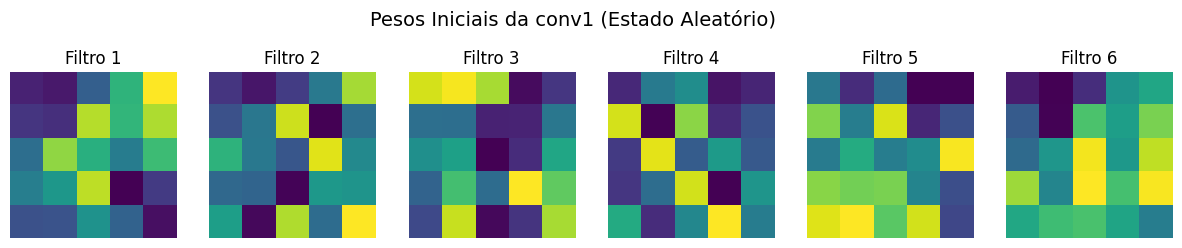

In [7]:
import matplotlib.pyplot as plt

# Extrair os pesos da camada conv1 sem manter o histórico de grafos do autograd (.detach())
weights = model.conv1.weight.detach().cpu().numpy()

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for i, ax in enumerate(axes):
    # A conv1 tem 6 filtros produzindo 1 canal por filtro de tamanho 5x5:
    # O shape é (out_channels=6, in_channels=1, H=5, W=5)
    ax.imshow(weights[i, 0], cmap='viridis')
    ax.axis('off')
    ax.set_title(f'Filtro {i+1}')

plt.suptitle('Pesos Iniciais da conv1 (Estado Aleatório)', fontsize=14)
plt.show()

---
## Treinamento

Treinamento do modelo no dataset **MNIST** (70 000 imagens de dígitos manuscritos 28×28).

As imagens originais são 28x28, e a classe `LeopaNet` agora usa `padding=2` na entrada para evitar perda nas bordas.

In [8]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

### Hiperparâmetros

In [9]:
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
NUM_EPOCHS = 10

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo: {device}")

Dispositivo: cpu


### Carregamento dos dados

In [10]:
transform = transforms.Compose([
    # Removemos o redimensionamento pois adicionamos padding=2 na primeira Conv!
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.1307,), std=(0.3081,)),
])

train_dataset = datasets.MNIST(root="./data", train=True,  download=True, transform=transform)
test_dataset  = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print(f"Treino: {len(train_dataset):,} amostras  |  Teste: {len(test_dataset):,} amostras")

Treino: 60,000 amostras  |  Teste: 10,000 amostras


### Visualização de Exemplos do Dataset

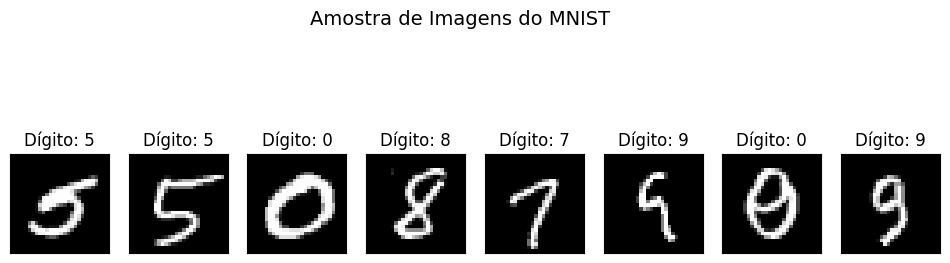

In [11]:
import matplotlib.pyplot as plt

# Obtém um batch (lote) de imagens de treinamento
dataiter = iter(train_loader)
images, labels = next(dataiter)

# Plota 8 exemplos desse lote
fig = plt.figure(figsize=(12, 4))
for idx in range(8):
    ax = fig.add_subplot(1, 8, idx+1, xticks=[], yticks=[])
    
    # Seleciona a imagem (1, H, W)
    img = images[idx]
    
    # Desnormaliza: img = img * std + mean (baseado nos valores de normalize)
    img = img * 0.3081 + 0.1307
    
    # Converte para array matplotlib usando squeeze para ser HxW (28x28)
    npimg = img.squeeze().numpy()
    
    # Exibe no subplot
    ax.imshow(npimg, cmap='gray')
    ax.set_title(f"Dígito: {labels[idx].item()}")

plt.suptitle("Amostra de Imagens do MNIST", fontsize=14)
plt.show()

### Modelo, Loss e Otimizador

In [12]:
model = LeopaNet().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

### Loop de Treinamento

In [13]:
for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc  = 100.0 * correct / total
    print(f"Época [{epoch:02d}/{NUM_EPOCHS}]  Loss: {epoch_loss:.4f}  Acurácia: {epoch_acc:.2f}%")

Época [01/10]  Loss: 0.2370  Acurácia: 92.67%
Época [02/10]  Loss: 0.0646  Acurácia: 98.01%
Época [03/10]  Loss: 0.0450  Acurácia: 98.56%
Época [04/10]  Loss: 0.0363  Acurácia: 98.83%
Época [05/10]  Loss: 0.0295  Acurácia: 99.02%
Época [06/10]  Loss: 0.0242  Acurácia: 99.18%
Época [07/10]  Loss: 0.0211  Acurácia: 99.32%
Época [08/10]  Loss: 0.0184  Acurácia: 99.40%
Época [09/10]  Loss: 0.0157  Acurácia: 99.50%
Época [10/10]  Loss: 0.0132  Acurácia: 99.55%


---
## Avaliação no conjunto de teste

In [14]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

test_acc = 100.0 * correct / total
print(f"Acurácia no teste: {test_acc:.2f}%")

Acurácia no teste: 98.92%


### Análise de Performance Detalhada: Matriz de Confusão e Relatório

---- RELATÓRIO DE PERFORMANCE DA I.A. ----
              precision    recall  f1-score   support

           0     0.9929    0.9949    0.9939       980
           1     0.9921    0.9965    0.9943      1135
           2     0.9903    0.9903    0.9903      1032
           3     0.9921    0.9901    0.9911      1010
           4     0.9888    0.9929    0.9909       982
           5     0.9942    0.9686    0.9813       892
           6     0.9916    0.9906    0.9911       958
           7     0.9912    0.9874    0.9893      1028
           8     0.9709    0.9918    0.9812       974
           9     0.9881    0.9861    0.9871      1009

    accuracy                         0.9892     10000
   macro avg     0.9892    0.9889    0.9890     10000
weighted avg     0.9892    0.9892    0.9892     10000



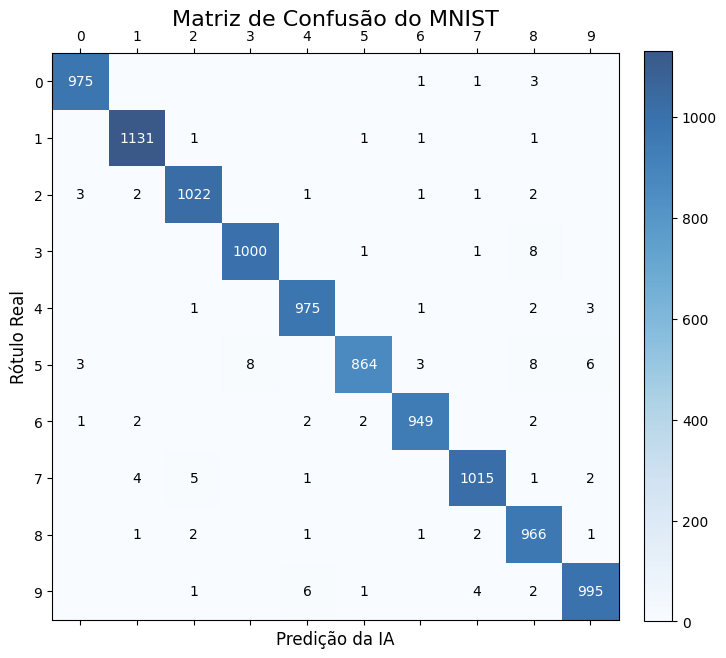

In [15]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

all_preds = []
all_labels = []
bad_images = []
bad_preds = []
bad_labels = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = outputs.max(1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        
        # Guardar alguns exemplos em que a rede errou a predição para exibir depois
        mask = preds != labels
        if mask.any() and len(bad_images) < 10:
            # pega apenas os erros desse batch
            bad_images.extend(images[mask].cpu().numpy())
            bad_preds.extend(preds[mask].cpu().numpy())
            bad_labels.extend(labels[mask].cpu().numpy())

print("---- RELATÓRIO DE PERFORMANCE DA I.A. ----")
print(classification_report(all_labels, all_preds, digits=4))

# -- Matriz de Confusão --
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(8, 8))
cax = ax.matshow(cm, cmap='Blues', alpha=0.8)
plt.title('Matriz de Confusão do MNIST', pad=20, fontsize=16)
fig.colorbar(cax, fraction=0.046, pad=0.04)

for i in range(10):
    for j in range(10):
        # Destacar números de predições corretas x erradas na matriz
        texto = str(cm[i, j])
        ax.text(j, i, texto if cm[i,j] > 0 else '', va='center', ha='center', 
                color='black' if cm[i,j] < 500 else 'white')

plt.xlabel('Predição da IA', fontsize=12)
plt.ylabel('Rótulo Real', fontsize=12)
plt.xticks(range(10))
plt.yticks(range(10))
plt.show()

### Analisando onde a LeopaNet falhou
Aqui separamos os primeiros 10 exemplos que a IA errou no conjunto de teste. Muitas vezes os rabiscos são difíceis de compreender até para humanos!

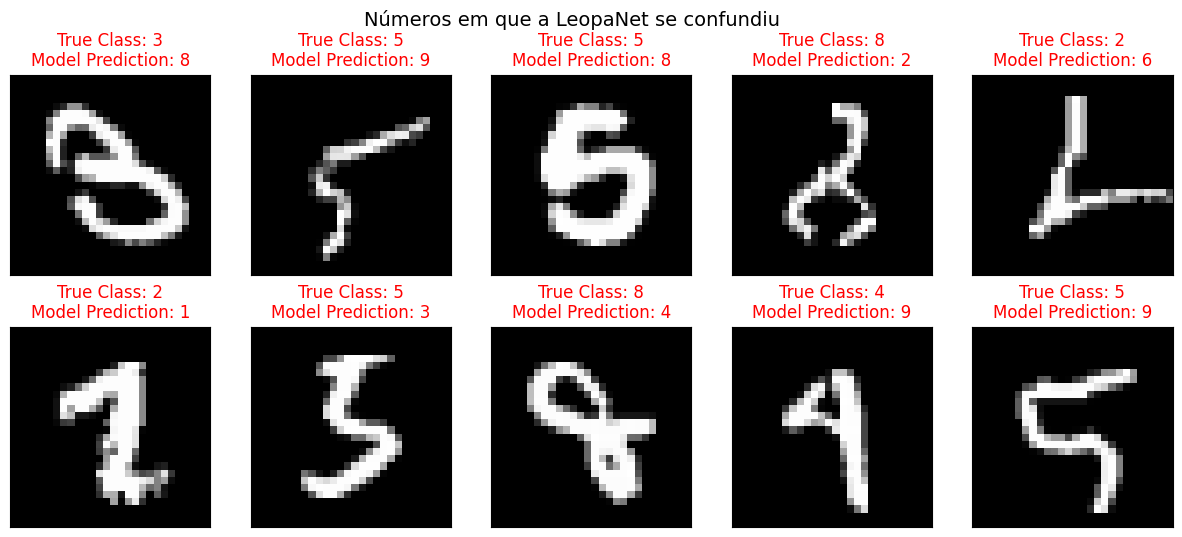

In [16]:
fig = plt.figure(figsize=(15, 6))
n_erros = min(10, len(bad_images))
for idx in range(n_erros):
    ax = fig.add_subplot(2, 5, idx+1, xticks=[], yticks=[])
    
    img = bad_images[idx][0] # Extrai apenas a matrix HxW
    img = img * 0.3081 + 0.1307 # Apenas para plotar na escala original
    
    ax.imshow(img, cmap='gray')
    ax.set_title(f"True Class: {bad_labels[idx]}\nModel Prediction: {bad_preds[idx]}", color="red")

if n_erros > 0:
    plt.suptitle("Números em que a LeopaNet se confundiu", fontsize=14)
else:
    plt.suptitle("Impressionante! Sem erros nos primeiros lotes capturados.", fontsize=14)
plt.show()

### Salvar o modelo treinado

In [17]:
torch.save(model.state_dict(), "leopanet_mnist.pth")
print("Modelo salvo em leopanet_mnist.pth")

Modelo salvo em leopanet_mnist.pth


### Carrega o modelo após uso
Para carregar o modelo posteriormente, instanciamos a arquitetura do modelo e usamos `load_state_dict` para carregar os pesos salvos.

In [18]:
import torch

# Instancia a mesma arquitetura do modelo
loaded_model = LeopaNet().to(device)

# Carrega os pesos salvos no arquivo
loaded_model.load_state_dict(torch.load("leopanet_mnist.pth", weights_only=True))
# Coloca o modelo em modo de avaliação (necessário para inferência)
loaded_model.eval()

print("Modelo carregado com sucesso a partir de leopanet_mnist.pth!")

Modelo carregado com sucesso a partir de leopanet_mnist.pth!


### Visualização das Ativações da Primeira Camada (Feature Maps)
Vamos passar uma imagem de exemplo pela primeira camada convolucional (`conv1`) para visualizar os feature maps (mapas de características) resultantes.

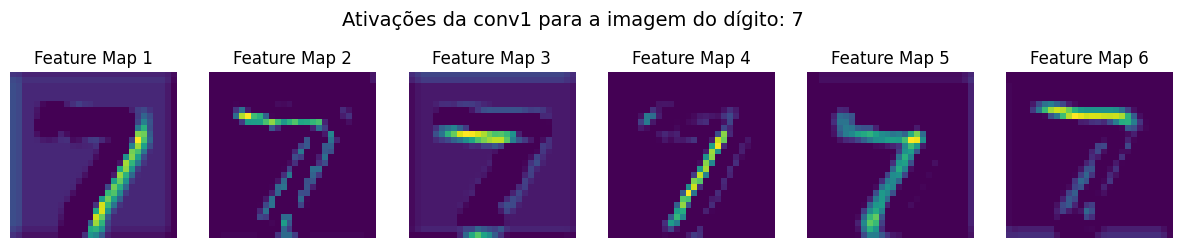

In [19]:
# Pega uma imagem do dataset de teste
dataiter = iter(test_loader)
images, labels = next(dataiter)
image = images[0].unsqueeze(0).to(device) # Ajustando o shape para (1, 1, 28, 28)

# Passa a imagem apenas pela primeira camada conv1 acompanhada da ativação ReLU
with torch.no_grad():
    activation = F.relu(loaded_model.conv1(image))
    
# activation tem o shape (1, out_channels=6, H=28, W=28)
feature_maps = activation.squeeze(0).cpu().numpy()

fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for i, ax in enumerate(axes):
    ax.imshow(feature_maps[i], cmap='viridis')
    ax.axis('off')
    ax.set_title(f'Feature Map {i+1}')

plt.suptitle(f'Ativações da conv1 para a imagem do dígito: {labels[0].item()}', fontsize=14)
plt.show()